# UCI HAR Seq2Seq PatchTST Transformer + Energy / Carbon Tracking

Expected files in one folder:

```text
PatchTST_backbone.py
PatchTST_layers.py
RevIN.py
train.npz
val.npz        
test.npz
warm_state.json  
```

Outputs are written to:

```text
./outputs/
├── carbon_logs/
├── models/
├── patchtst_har_carbon_summary.csv
├── patchtst_har_inference_per_sample_summary.csv
└── plots / inference summaries
```


## 0. Install tracking libraries if missing

In [40]:
# Run this cell once on the Google VM if CodeCarbon / CarbonTracker are not installed.
# It is safe to re-run: packages already installed will be skipped by pip.

import importlib.util
import subprocess
import sys

packages = []
if importlib.util.find_spec("codecarbon") is None:
    packages.append("codecarbon")
if importlib.util.find_spec("carbontracker") is None:
    packages.append("carbontracker")

if packages:
    print("Installing:", packages)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])
else:
    print("CodeCarbon and CarbonTracker are already installed.")


## 1. Imports, paths, and backbone loading

In [ ]:
import os
import sys
import gc
import json
import time
import shutil
import socket
import random
import importlib
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, recall_score, precision_score

try:
    from codecarbon import OfflineEmissionsTracker
    CODECARBON_AVAILABLE = True
except Exception as e:
    CODECARBON_AVAILABLE = False
    print("CodeCarbon unavailable:", repr(e))

try:
    from carbontracker.tracker import CarbonTracker
    CARBONTRACKER_AVAILABLE = True
except Exception as e:
    CARBONTRACKER_AVAILABLE = False
    print("CarbonTracker unavailable:", repr(e))



PROJECT_ROOT = Path.cwd().resolve()

BACKBONE_FILES = [
    "PatchTST_backbone.py",
    "PatchTST_layers.py",
    "RevIN.py",
]

DATA_FILES_ALWAYS = [
    "train.npz",
    "test.npz",
]

VAL_FILE_CANDIDATES = ["val.npz", "valid.npz"]


def has_required_files(folder: Path) -> bool:
    folder = Path(folder)
    if not folder.exists() or not folder.is_dir():
        return False

    has_backbone = all((folder / f).exists() for f in BACKBONE_FILES)
    has_data = all((folder / f).exists() for f in DATA_FILES_ALWAYS)
    has_val = any((folder / f).exists() for f in VAL_FILE_CANDIDATES)

    return has_backbone and has_data and has_val


def find_input_dir() -> Path:
    candidates = [
        PROJECT_ROOT,
        PROJECT_ROOT / "files",
        PROJECT_ROOT / "ucihar",
        PROJECT_ROOT / "data",
        PROJECT_ROOT / "datasets",
        PROJECT_ROOT / "datasets" / "ucihar",
        Path("/home/jupyter"),
        Path("/home/jupyter/files"),
        Path("/home/jupyter/ucihar"),
        Path("/home/jupyter/data"),
        Path("/home/jupyter/datasets"),
        Path("/home/jupyter/datasets/ucihar"),
    ]

    for folder in candidates:
        if has_required_files(folder):
            return folder.resolve()

    # Fallback: search recursively from the current notebook folder and /home/jupyter.
    # This is useful when files were uploaded inside a custom folder from the Jupyter UI.
    search_roots = []
    for root in [PROJECT_ROOT, Path("/home/jupyter")]:
        if root.exists() and root not in search_roots:
            search_roots.append(root)

    for root in search_roots:
        for train_path in root.rglob("train.npz"):
            folder = train_path.parent
            if has_required_files(folder):
                return folder.resolve()

    expected = BACKBONE_FILES + DATA_FILES_ALWAYS + ["val.npz or valid.npz"]
    raise FileNotFoundError(
        "Could not auto-detect the UCI HAR input folder.\n"
        f"Notebook folder: {PROJECT_ROOT}\n"
        f"Expected all of these files in the same folder: {expected}\n"
        "Fix: upload the files to the Jupyter Files panel, or set INPUT_DIR manually in this cell."
    )


INPUT_DIR = find_input_dir()

WORK_DIR = PROJECT_ROOT / "outputs"
CARBON_LOG_DIR = WORK_DIR / "carbon_logs"
MODEL_DIR = WORK_DIR / "models"

CARBON_LOG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("INPUT_DIR   :", INPUT_DIR)
print("WORK_DIR    :", WORK_DIR)

required_files_display = BACKBONE_FILES + DATA_FILES_ALWAYS + ["val.npz or valid.npz"]
print("\nRequired files:", required_files_display)
print("Detected files:")
for f in BACKBONE_FILES + DATA_FILES_ALWAYS + VAL_FILE_CANDIDATES + ["warm_state.json"]:
    print(f"  {f:22s}", "FOUND" if (INPUT_DIR / f).exists() else "-")

# Copy backbone modules into WORK_DIR so imports are stable even if the notebook
# is launched from a different folder.
for f in BACKBONE_FILES:
    src = INPUT_DIR / f
    dst = WORK_DIR / f
    if src.resolve() != dst.resolve():
        shutil.copy2(src, dst)

os.chdir(WORK_DIR)
sys.path.insert(0, str(WORK_DIR))

for module_name in ["PatchTST_backbone", "PatchTST_layers", "RevIN"]:
    if module_name in sys.modules:
        del sys.modules[module_name]

import PatchTST_backbone
importlib.reload(PatchTST_backbone)

print("\nUsing backbone:", PatchTST_backbone.__file__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Machine:", socket.gethostname())


Using backbone: /kaggle/working/PatchTST_backbone.py
CUDA available: True
GPU: Tesla T4
Machine: d80f2a6777bc


## 2. Reproducibility and constants

In [42]:
IGNORE_INDEX = -100

ACTIVITY_NAMES = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING",
]

N_CLASSES = len(ACTIVITY_NAMES)

# Offline grid assumption for CodeCarbon.
# Change this if your Google VM is in another region and you want a different
# grid-intensity assumption. Use a 3-letter ISO country code.
CARBON_COUNTRY_ISO3 = "FRA"

def reset_seeds(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False

reset_seeds(42)

## 3. Load UCI HAR seq2seq arrays from `.npz`

In [43]:
VAL_FILE = "val.npz" if (INPUT_DIR / "val.npz").exists() else "valid.npz"

train_npz = np.load(INPUT_DIR / "train.npz")
valid_npz = np.load(INPUT_DIR / VAL_FILE)
test_npz  = np.load(INPUT_DIR / "test.npz")

print("Validation file:", VAL_FILE)
print("train keys:", train_npz.files)
print("valid keys:", valid_npz.files)
print("test keys :", test_npz.files)

X_train = train_npz["X"]
y_train = train_npz["y_activity"]
y_transition_train = train_npz["y_transition"]
y_edge_train = train_npz["y_edge"]
mask_train = train_npz["valid_mask"].astype(bool)
train_subjects = train_npz["subject_ids"]
train_lengths = train_npz["lengths"]

X_val = valid_npz["X"]
y_val = valid_npz["y_activity"]
y_transition_val = valid_npz["y_transition"]
y_edge_val = valid_npz["y_edge"]
mask_val = valid_npz["valid_mask"].astype(bool)
val_subjects = valid_npz["subject_ids"]
val_lengths = valid_npz["lengths"]

X_test = test_npz["X"]
y_test = test_npz["y_activity"]
y_transition_test = test_npz["y_transition"]
y_edge_test = test_npz["y_edge"]
mask_test = test_npz["valid_mask"].astype(bool)
test_subjects = test_npz["subject_ids"]
test_lengths = test_npz["lengths"]

SEQ_LEN = X_train.shape[2]
N_CHANNELS = X_train.shape[1]
N_TRANSITION_CLASSES = y_edge_train.shape[-1]

print("\nShapes:")
print("X_train      :", X_train.shape)
print("y_train      :", y_train.shape)
print("y_edge_train :", y_edge_train.shape)
print("mask_train   :", mask_train.shape)
print()
print(f"SEQ_LEN={SEQ_LEN}, N_CHANNELS={N_CHANNELS}, N_CLASSES={N_CLASSES}, N_TRANSITION_CLASSES={N_TRANSITION_CLASSES}")

if (INPUT_DIR / "warm_state.json").exists():
    with open(INPUT_DIR / "warm_state.json") as f:
        warm_state = json.load(f)
    print("\nwarm_state.json:")
    print(json.dumps(warm_state, indent=2)[:2000])
else:
    warm_state = {}


train keys: ['X', 'y_activity', 'y_transition', 'y_edge', 'valid_mask', 'subject_ids', 'lengths']
valid keys: ['X', 'y_activity', 'y_transition', 'y_edge', 'valid_mask', 'subject_ids', 'lengths']
test keys : ['X', 'y_activity', 'y_transition', 'y_edge', 'valid_mask', 'subject_ids', 'lengths']

Shapes:
X_train      : (17, 54, 409)
y_train      : (17, 409)
y_edge_train : (17, 409, 6)
mask_train   : (17, 409)

SEQ_LEN=409, N_CHANNELS=54, N_CLASSES=6, N_TRANSITION_CLASSES=6

warm_state.json:
{
  "dataset_type": "uci_har_seq2seq_transformer",
  "HAR_ROOT": "/Users/enorabarbier/Documents/1.M2 Courses/CRP/CRP_SLB/datasets/medical/UCI HAR Dataset",
  "SAVE_DIR": "har_seq2seq_transformer",
  "IGNORE_INDEX": -100,
  "FEATURE_MODE": "stats",
  "WINDOW_LEN": 128,
  "RAW_CHANNELS": [
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",
    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z",
    "total_acc_x",
    "total_acc_y",
    "total_acc_z"
  ],
  "FEATURES_GEOX": [
    "body_acc_x_mean",
  

## 4. Dataset and dataloaders

In [44]:
class HARDataset(Dataset):
    """
    UCI HAR seq2seq dataset.

    Returns:
        x:          (n_channels, seq_len)
        y:          (seq_len,)
        y_edge:     (seq_len, n_transition_classes)
        valid_mask: (seq_len,)
    """
    def __init__(
        self,
        X,
        y_activity,
        y_edge,
        valid_mask,
        noise_std: float = 0.0,
        training: bool = False,
    ):
        assert X.ndim == 3, f"Expected X as (N, C, T), got {X.shape}"
        assert y_activity.ndim == 2, f"Expected y as (N, T), got {y_activity.shape}"
        assert y_edge.ndim == 3, f"Expected y_edge as (N, T, K), got {y_edge.shape}"
        assert valid_mask.ndim == 2, f"Expected mask as (N, T), got {valid_mask.shape}"
        assert X.shape[0] == y_activity.shape[0] == y_edge.shape[0] == valid_mask.shape[0]
        assert X.shape[2] == y_activity.shape[1] == y_edge.shape[1] == valid_mask.shape[1]

        self.X = torch.from_numpy(X.astype(np.float32))
        self.y = torch.from_numpy(y_activity.astype(np.int64))
        self.y_edge = torch.from_numpy(y_edge.astype(np.float32))
        self.valid_mask = torch.from_numpy(valid_mask.astype(bool))

        self.noise_std = float(noise_std)
        self.training = bool(training)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        x = self.X[idx].clone()
        y = self.y[idx].clone()
        y_edge = self.y_edge[idx].clone()
        mask = self.valid_mask[idx].clone()

        if self.training and self.noise_std > 0:
            channel_std = x.std(dim=-1, keepdim=True).clamp(min=1e-6)
            noise = torch.randn_like(x) * channel_std * self.noise_std
            x = x + noise

        return x, y, y_edge, mask


BATCH_SIZE = 4
NOISE_STD = 0.02

train_ds = HARDataset(X_train, y_train, y_edge_train, mask_train, noise_std=NOISE_STD, training=True)
val_ds   = HARDataset(X_val,   y_val,   y_edge_val,   mask_val,   training=False)
test_ds  = HARDataset(X_test,  y_test,  y_edge_test,  mask_test,  training=False)

train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_dl   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_dl  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

batch = next(iter(train_dl))
print([x.shape for x in batch])

[torch.Size([4, 54, 409]), torch.Size([4, 409]), torch.Size([4, 409, 6]), torch.Size([4, 409])]


## 5. PatchTST seq2seq model for UCI HAR

In [45]:
class SegmentationHead(nn.Module):
    def __init__(
        self,
        feat_dim: int,
        n_vars: int,
        patch_num: int,
        seq_len: int,
        n_classes: int,
        dropout: float = 0.1,
        hidden: int = 256,
    ):
        super().__init__()
        self.seq_len = seq_len
        self.patch_num = patch_num

        self.mlp = nn.Sequential(
            nn.Linear(feat_dim * n_vars, hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, n_classes),
        )
        self.upsample = nn.Upsample(size=seq_len, mode="linear", align_corners=False)

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        bs = z.size(0)
        z = z.permute(0, 3, 1, 2).reshape(bs, self.patch_num, -1)
        z = self.mlp(z)
        z = self.upsample(z.permute(0, 2, 1))
        return z.permute(0, 2, 1)


class TransitionHead(nn.Module):
    def __init__(
        self,
        feat_dim: int,
        n_vars: int,
        patch_num: int,
        seq_len: int,
        n_transition_classes: int,
        dropout: float = 0.1,
        hidden: int = 256,
    ):
        super().__init__()
        self.seq_len = seq_len
        self.patch_num = patch_num

        self.mlp = nn.Sequential(
            nn.Linear(feat_dim * n_vars, hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden // 2, n_transition_classes),
        )
        self.upsample = nn.Upsample(size=seq_len, mode="linear", align_corners=False)

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        bs = z.size(0)
        z = z.permute(0, 3, 1, 2).reshape(bs, self.patch_num, -1)
        z = self.mlp(z)
        z = self.upsample(z.permute(0, 2, 1))
        return z.permute(0, 2, 1)


class PatchTSTHARSeq2Seq(nn.Module):
    """
    PatchTST encoder for UCI HAR sequence labeling.

    Input:
        x: (batch_size, n_channels, seq_len)

    Outputs:
        activity_logits:   (batch_size, seq_len, 6)
        transition_logits: (batch_size, seq_len, n_transition_classes)
    """
    def __init__(
        self,
        seq_len: int,
        n_channels: int,
        n_activity_classes: int = 6,
        n_transition_classes: int = 7,
        patch_len: int = 16,
        stride: int = 8,
        d_model: int = 128,
        n_heads: int = 8,
        n_layers: int = 3,
        d_ff: int = 256,
        dropout: float = 0.1,
        head_dropout: float = 0.1,
        pe: str = "zeros",
        learn_pe: bool = True,
        revin: bool = False,
    ):
        super().__init__()
        from PatchTST_backbone import PatchTST_backbone

        patch_num = int((seq_len - patch_len) / stride + 1) + 1

        self.seq_len = seq_len
        self.n_channels = n_channels
        self.n_activity_classes = n_activity_classes
        self.n_transition_classes = n_transition_classes

        backbone_kwargs = dict(
            c_in=n_channels,
            context_window=seq_len,
            target_window=seq_len,
            patch_len=patch_len,
            stride=stride,
            d_model=d_model,
            n_heads=n_heads,
            n_layers=n_layers,
            d_ff=d_ff,
            norm="BatchNorm",
            dropout=dropout,
            fc_dropout=dropout,
            head_dropout=head_dropout,
            head_type="flatten",
            individual=False,
            revin=revin,
            padding_patch="end",
            pe=pe,
            learn_pe=learn_pe,
            res_attention=True,
        )

        try:
            self.backbone = PatchTST_backbone(n_markers=0, **backbone_kwargs)
        except TypeError:
            self.backbone = PatchTST_backbone(**backbone_kwargs)

        if hasattr(self.backbone, "head"):
            del self.backbone.head

        self.activity_head = SegmentationHead(
            feat_dim=d_model,
            n_vars=n_channels,
            patch_num=patch_num,
            seq_len=seq_len,
            n_classes=n_activity_classes,
            dropout=head_dropout,
        )

        self.transition_head = TransitionHead(
            feat_dim=d_model,
            n_vars=n_channels,
            patch_num=patch_num,
            seq_len=seq_len,
            n_transition_classes=n_transition_classes,
            dropout=head_dropout,
        )

    def _encode(self, x: torch.Tensor) -> torch.Tensor:
        b = self.backbone

        if getattr(b, "padding_patch", None) == "end":
            x = b.padding_patch_layer(x)

        x = x.unfold(dimension=-1, size=b.patch_len, step=b.stride)
        x = x.permute(0, 1, 3, 2)

        if getattr(b, "key_padding_mask", None) == "auto":
            x, kpm = b.key_padding_masking(x)
        else:
            kpm = None

        x = torch.nan_to_num(x, nan=0.0)
        z = b.backbone(x, key_padding_mask_tensor=kpm)
        return z

    def forward(self, x: torch.Tensor):
        z = self._encode(x)
        activity_logits = self.activity_head(z)
        transition_logits = self.transition_head(z)
        return activity_logits, transition_logits

## 6. Losses and metrics

In [46]:
def effective_number_weights(y, valid_mask, n_classes, beta=0.9999, device=torch.device("cpu")):
    valid_y = y[valid_mask].flatten()
    counts = np.bincount(valid_y, minlength=n_classes).astype(np.float64)
    counts = np.where(counts == 0, 1, counts)

    effective = 1.0 - np.power(beta, counts)
    weights = (1.0 - beta) / effective
    weights = weights / weights.mean()

    print("Class counts:", dict(enumerate(counts.astype(int))))
    print("Class weights:", dict(enumerate(np.round(weights, 4))))

    return torch.tensor(weights.astype(np.float32), device=device)


def activity_loss(activity_logits, y_activity, valid_mask, class_weights=None, ignore_index=IGNORE_INDEX):
    criterion = nn.CrossEntropyLoss(weight=class_weights, ignore_index=ignore_index)
    logits_flat = activity_logits[valid_mask]
    y_flat = y_activity[valid_mask]
    return criterion(logits_flat, y_flat)


def transition_location_loss(transition_logits, y_edge, valid_mask):
    losses = []
    B, T, K = transition_logits.shape

    for k in range(K):
        logits_k = transition_logits[:, :, k]
        target_k = y_edge[:, :, k]

        valid_k = (target_k >= 0) & valid_mask
        positive_mass = (target_k.clamp(min=0) * valid_k.float()).sum(dim=1)
        has_transition = positive_mass > 0

        if not has_transition.any():
            continue

        logits_k = logits_k[has_transition]
        target_k = target_k[has_transition].clamp(min=0.0)
        valid_k = valid_k[has_transition]

        logits_k = logits_k.masked_fill(~valid_k, -1e9)
        target_k = target_k * valid_k.float()

        target_dist = target_k / target_k.sum(dim=1, keepdim=True).clamp(min=1e-8)
        log_probs = torch.log_softmax(logits_k, dim=1)
        loss_k = -(target_dist * log_probs).sum(dim=1).mean()
        losses.append(loss_k)

    if len(losses) == 0:
        return transition_logits.sum() * 0.0

    return torch.stack(losses).mean()


@torch.no_grad()
def evaluate_activity_model(model, loader, device, activity_names=ACTIVITY_NAMES, verbose=True):
    model.eval()
    all_true = []
    all_pred = []
    total_loss = 0.0
    total_n = 0

    for X_batch, y_batch, y_edge_batch, mask_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        mask_batch = mask_batch.to(device)

        activity_logits, transition_logits = model(X_batch)
        loss = activity_loss(activity_logits, y_batch, mask_batch, class_weights=None)
        preds = activity_logits.argmax(dim=-1)

        all_true.extend(y_batch[mask_batch].detach().cpu().numpy())
        all_pred.extend(preds[mask_batch].detach().cpu().numpy())

        bs = X_batch.size(0)
        total_loss += loss.item() * bs
        total_n += bs

    all_true = np.array(all_true)
    all_pred = np.array(all_pred)

    metrics = {
        "loss": total_loss / max(total_n, 1),
        "accuracy": accuracy_score(all_true, all_pred),
        "macro_precision": precision_score(all_true, all_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(all_true, all_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(all_true, all_pred, average="macro", zero_division=0),
    }

    if verbose:
        print(f"Loss: {metrics['loss']:.4f}")
        print(f"Accuracy: {metrics['accuracy']:.4f}")
        print(f"Macro recall: {metrics['macro_recall']:.4f}")
        print(f"Macro F1: {metrics['macro_f1']:.4f}")
        print("\nClassification report:")
        print(classification_report(all_true, all_pred, labels=list(range(len(activity_names))), target_names=activity_names, zero_division=0))
        print("\nConfusion matrix:")
        print(confusion_matrix(all_true, all_pred, labels=list(range(len(activity_names)))))

    return metrics

## 7. Carbon and energy tracking helpers

In [47]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def _read_codecarbon_csv(path):
    """Read the last row of a CodeCarbon CSV file."""
    path = Path(path)
    out = {
        "emissions_kg": np.nan,
        "emissions_g": np.nan,
        "energy_kwh": np.nan,
        "cpu_kwh": np.nan,
        "gpu_kwh": np.nan,
        "ram_kwh": np.nan,
        "country": None,
        "region": None,
    }

    if not path.exists():
        return out

    df = pd.read_csv(path)
    if len(df) == 0:
        return out

    r = df.iloc[-1]
    emissions_kg = float(r.get("emissions", np.nan))
    out.update({
        "emissions_kg": emissions_kg,
        "emissions_g": emissions_kg * 1000 if np.isfinite(emissions_kg) else np.nan,
        "energy_kwh": float(r.get("energy_consumed", np.nan)),
        "cpu_kwh": float(r.get("cpu_energy", np.nan)),
        "gpu_kwh": float(r.get("gpu_energy", np.nan)),
        "ram_kwh": float(r.get("ram_energy", np.nan)),
        "country": r.get("country_name", None),
        "region": r.get("region", None),
    })
    return out


def _parse_carbontracker_log(log_dir, prefix):
    """
    Robustly parse CarbonTracker logs.
    CarbonTracker log text differs slightly by version, so this parser tries
    several common formats and returns NaN if the library did not write usable values.
    """
    log_dir = Path(log_dir)
    files = sorted(
        list(log_dir.glob(f"{prefix}*carbontracker*.log")) + list(log_dir.glob(f"{prefix}*.log")),
        key=lambda p: p.stat().st_mtime,
        reverse=True,
    )

    if not files:
        return {"energy_kwh": np.nan, "emissions_g": np.nan, "log_file": None}

    import re

    for path in files:
        text = path.read_text(errors="ignore")

        # Common CarbonTracker summaries:
        # "Actual consumption ... Energy: X kWh ... CO2eq: Y g"
        patterns = [
            r"Actual consumption.*?Energy:\s*([\d.eE+-]+)\s*kWh.*?(?:CO2eq|CO2):\s*([\d.eE+-]+)\s*g",
            r"Predicted consumption.*?Energy:\s*([\d.eE+-]+)\s*kWh.*?(?:CO2eq|CO2):\s*([\d.eE+-]+)\s*g",
            r"Energy:\s*([\d.eE+-]+)\s*kWh.*?(?:CO2eq|CO2):\s*([\d.eE+-]+)\s*g",
            r"([\d.eE+-]+)\s*kWh.*?([\d.eE+-]+)\s*g\s*(?:CO2eq|CO2|of\s*CO2)",
        ]

        for pattern in patterns:
            m = re.search(pattern, text, re.DOTALL | re.IGNORECASE)
            if m:
                return {
                    "energy_kwh": float(m.group(1)),
                    "emissions_g": float(m.group(2)),
                    "log_file": str(path),
                }

        # Fallback: use the last energy and CO2-like values found in the file.
        kwh_matches = re.findall(r"([\d.eE+-]+)\s*kWh", text, re.IGNORECASE)
        co2_matches = re.findall(r"([\d.eE+-]+)\s*g\s*(?:CO2eq|CO2|of\s*CO2)", text, re.IGNORECASE)
        if kwh_matches and co2_matches:
            return {
                "energy_kwh": float(kwh_matches[-1]),
                "emissions_g": float(co2_matches[-1]),
                "log_file": str(path),
            }

    return {"energy_kwh": np.nan, "emissions_g": np.nan, "log_file": str(files[0])}


def start_codecarbon_tracker(project_name, output_file):
    if not CODECARBON_AVAILABLE:
        return None

    return OfflineEmissionsTracker(
        country_iso_code=CARBON_COUNTRY_ISO3,
        project_name=project_name,
        output_dir=str(CARBON_LOG_DIR),
        output_file=output_file,
        log_level="error",
        save_to_file=True,
    )


class PhaseCarbonContext:
    """
    Tracks one phase with both CodeCarbon and CarbonTracker.

    Important:
    - Use one PhaseCarbonContext for training.
    - Use a separate PhaseCarbonContext for inference.
    - Call epoch_start() / epoch_end() inside the measured block.
      CarbonTracker only produces useful values when epochs are explicitly marked.
    """
    def __init__(self, phase_name, epochs=1):
        self.phase_name = phase_name
        self.epochs = int(max(epochs, 1))
        self.prefix = phase_name.replace("/", "_").replace(" ", "_")
        self.cc_file = f"{self.prefix}_codecarbon.csv"
        self.cc_tracker = None
        self.ct_tracker = None
        self.start_time = None
        self.end_time = None

    def start(self):
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
            torch.cuda.synchronize()

        self.start_time = time.time()

        # CodeCarbon starts/stops around the whole phase.
        self.cc_tracker = start_codecarbon_tracker(project_name=self.phase_name, output_file=self.cc_file)
        if self.cc_tracker is not None:
            self.cc_tracker.start()

        # CarbonTracker should be started by creating the tracker; epochs are then marked below.
        if CARBONTRACKER_AVAILABLE:
            try:
                self.ct_tracker = CarbonTracker(
                    epochs=self.epochs,
                    monitor_epochs=1,
                    log_dir=str(CARBON_LOG_DIR),
                    log_file_prefix=self.prefix,
                    verbose=0,
                )
            except Exception as e:
                print(f"[CarbonTracker] Could not initialize for {self.phase_name}: {repr(e)}")
                self.ct_tracker = None

    def epoch_start(self):
        if self.ct_tracker is not None:
            try:
                self.ct_tracker.epoch_start()
            except Exception as e:
                print(f"[CarbonTracker] epoch_start failed for {self.phase_name}: {repr(e)}")

    def epoch_end(self):
        if self.ct_tracker is not None:
            try:
                self.ct_tracker.epoch_end()
            except Exception as e:
                print(f"[CarbonTracker] epoch_end failed for {self.phase_name}: {repr(e)}")

    def stop(self):
        if torch.cuda.is_available():
            torch.cuda.synchronize()

        self.end_time = time.time()

        if self.cc_tracker is not None:
            try:
                self.cc_tracker.stop()
            except Exception as e:
                print(f"[CodeCarbon] Could not stop cleanly for {self.phase_name}: {repr(e)}")

        if self.ct_tracker is not None:
            try:
                self.ct_tracker.stop()
            except Exception as e:
                print(f"[CarbonTracker] Could not stop cleanly for {self.phase_name}: {repr(e)}")

        cc = _read_codecarbon_csv(CARBON_LOG_DIR / self.cc_file)
        ct = _parse_carbontracker_log(CARBON_LOG_DIR, self.prefix)

        return {
            "phase": self.phase_name,
            "duration_s": self.end_time - self.start_time if self.end_time and self.start_time else np.nan,
            "cc_energy_kwh": cc["energy_kwh"],
            "cc_energy_wh": cc["energy_kwh"] * 1000 if np.isfinite(cc["energy_kwh"]) else np.nan,
            "cc_emissions_g": cc["emissions_g"],
            "cc_cpu_kwh": cc["cpu_kwh"],
            "cc_gpu_kwh": cc["gpu_kwh"],
            "cc_ram_kwh": cc["ram_kwh"],
            "cc_country": cc["country"],
            "cc_region": cc["region"],
            "ct_energy_kwh": ct["energy_kwh"],
            "ct_energy_wh": ct["energy_kwh"] * 1000 if np.isfinite(ct["energy_kwh"]) else np.nan,
            "ct_emissions_g": ct["emissions_g"],
            "ct_log_file": ct["log_file"],
        }

## 8. Training and inference with carbon tracking

In [48]:
def train_one_epoch(model, loader, optimizer, device, class_weights=None, activity_weight=1.0, transition_weight=0.0):
    model.train()
    total_loss = 0.0
    total_activity = 0.0
    total_transition = 0.0
    total_n = 0

    for X_batch, y_batch, y_edge_batch, mask_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        y_edge_batch = y_edge_batch.to(device)
        mask_batch = mask_batch.to(device)

        optimizer.zero_grad()
        activity_logits, transition_logits = model(X_batch)

        loss_activity = activity_loss(activity_logits, y_batch, mask_batch, class_weights=class_weights)

        if transition_weight > 0:
            loss_transition = transition_location_loss(transition_logits, y_edge_batch, mask_batch)
        else:
            loss_transition = transition_logits.sum() * 0.0

        loss = activity_weight * loss_activity + transition_weight * loss_transition
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        bs = X_batch.size(0)
        total_loss += loss.item() * bs
        total_activity += loss_activity.item() * bs
        total_transition += loss_transition.item() * bs
        total_n += bs

    return {
        "loss": total_loss / max(total_n, 1),
        "activity_loss": total_activity / max(total_n, 1),
        "transition_loss": total_transition / max(total_n, 1),
    }


def train_model_with_tracking(
    model,
    train_dl,
    val_dl,
    y_train,
    mask_train,
    epochs=25,
    lr=1e-4,
    weight_decay=1e-4,
    beta=0.9999,
    transition_weight=0.0,
    save_path="patchtst_har_seq2seq.pt",
):
    """
    Train the model and measure the full training phase with CodeCarbon + CarbonTracker.

    The measured training phase includes:
    - forward/backward passes on train_dl
    - optimizer/scheduler steps
    - validation evaluation done at the end of each epoch
    - model checkpoint saving

    If you want to measure only backward training without validation, move the validation block
    outside carbon.epoch_start()/carbon.epoch_end().
    """
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("Training on:", device)

    model = model.to(device)

    class_weights = effective_number_weights(y_train, mask_train, n_classes=N_CLASSES, beta=beta, device=device)

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    best_acc = -1.0
    best_state = None
    history = []

    carbon = PhaseCarbonContext("patchtst_har_training", epochs=epochs)
    carbon.start()

    try:
        for epoch in range(1, epochs + 1):
            # CarbonTracker needs explicit epoch boundaries to measure training.
            carbon.epoch_start()

            train_metrics = train_one_epoch(
                model=model,
                loader=train_dl,
                optimizer=optimizer,
                device=device,
                class_weights=class_weights,
                activity_weight=1.0,
                transition_weight=transition_weight,
            )

            scheduler.step()

            val_metrics = evaluate_activity_model(model, val_dl, device=device, verbose=False)

            if val_metrics["accuracy"] > best_acc:
                best_acc = val_metrics["accuracy"]
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                torch.save(best_state, MODEL_DIR / save_path)
                saved_msg = f"  -> Saved best model: {MODEL_DIR / save_path} | val_acc={best_acc:.4f}"
            else:
                saved_msg = None

            carbon.epoch_end()

            row = {
                "epoch": epoch,
                **{f"train_{k}": v for k, v in train_metrics.items()},
                **{f"val_{k}": v for k, v in val_metrics.items()},
            }
            history.append(row)

            print(
                f"Epoch {epoch:03d}/{epochs} | "
                f"train_loss={train_metrics['loss']:.4f} | "
                f"val_loss={val_metrics['loss']:.4f} | "
                f"val_acc={val_metrics['accuracy']:.4f} | "
                f"val_macro_recall={val_metrics['macro_recall']:.4f} | "
                f"val_macro_f1={val_metrics['macro_f1']:.4f}"
            )
            if saved_msg is not None:
                print(saved_msg)

    finally:
        training_carbon_summary = carbon.stop()

    if best_state is not None:
        model.load_state_dict(best_state)

    model = model.to(device)
    history_df = pd.DataFrame(history)
    history_df.to_csv(WORK_DIR / "training_history.csv", index=False)

    return model, history_df, training_carbon_summary


@torch.no_grad()
def run_inference_with_tracking(model, test_dl, repeats=1):
    """
    Run test inference and measure the full inference phase with CodeCarbon + CarbonTracker.

    repeats > 1 can make inference energy easier to measure because a single test pass can
    be too short for reliable hardware polling.
    """
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    model.eval()

    repeats = int(max(repeats, 1))
    carbon = PhaseCarbonContext("patchtst_har_inference", epochs=repeats)
    carbon.start()

    all_true, all_pred = [], []

    try:
        for r in range(repeats):
            # CarbonTracker also needs epoch boundaries for inference.
            # Here, each repeated full pass over test_dl is treated as one measured epoch.
            carbon.epoch_start()

            for X_batch, y_batch, y_edge_batch, mask_batch in test_dl:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)
                mask_batch = mask_batch.to(device)

                activity_logits, transition_logits = model(X_batch)
                preds = activity_logits.argmax(dim=-1)

                # Store predictions only once; repeated passes are only for more stable energy tracking.
                if r == 0:
                    all_true.extend(y_batch[mask_batch].detach().cpu().numpy())
                    all_pred.extend(preds[mask_batch].detach().cpu().numpy())

            carbon.epoch_end()

    finally:
        inference_carbon_summary = carbon.stop()

    all_true = np.array(all_true)
    all_pred = np.array(all_pred)

    metrics = {
        "accuracy": accuracy_score(all_true, all_pred),
        "macro_precision": precision_score(all_true, all_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(all_true, all_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(all_true, all_pred, average="macro", zero_division=0),
        "n_repeats": repeats,
        "n_positions": len(all_true),
    }

    return metrics, inference_carbon_summary

## 9. Build model

In [49]:
reset_seeds(42)

model = PatchTSTHARSeq2Seq(
    seq_len=SEQ_LEN,
    n_channels=N_CHANNELS,
    n_activity_classes=N_CLASSES,
    n_transition_classes=N_TRANSITION_CLASSES,
    patch_len=16,
    stride=8,
    d_model=128,
    n_heads=8,
    n_layers=3,
    d_ff=256,
    dropout=0.1,
    head_dropout=0.1,
    pe="zeros",
    learn_pe=True,
    revin=False,
)

print("Trainable parameters:", count_parameters(model))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

Xb, yb, yeb, mb = next(iter(train_dl))
with torch.no_grad():
    activity_logits, transition_logits = model(Xb.to(device))

print("activity_logits  :", activity_logits.shape)
print("transition_logits:", transition_logits.shape)

patch_num=51, head_nf=102
Trainable parameters: 3981070
activity_logits  : torch.Size([4, 409, 6])
transition_logits: torch.Size([4, 409, 6])


## 10. Run tracked training

In [ ]:
EPOCHS = 20
LR = 1e-4
WEIGHT_DECAY = 1e-4
BETA = 0.9999

TRANSITION_WEIGHT = 0.0

model, history_df, training_carbon = train_model_with_tracking(
    model=model,
    train_dl=train_dl,
    val_dl=val_dl,
    y_train=y_train,
    mask_train=mask_train,
    epochs=EPOCHS,
    lr=LR,
    weight_decay=WEIGHT_DECAY,
    beta=BETA,
    transition_weight=TRANSITION_WEIGHT,
    save_path="patchtst_har_seq2seq.pt",
)

print("\nTraining carbon summary:")
print(json.dumps(training_carbon, indent=2, default=str))

Training on: cuda
Class counts: {0: np.int64(996), 1: np.int64(866), 2: np.int64(800), 3: np.int64(1029), 4: np.int64(1092), 5: np.int64(1119)}
Class weights: {0: np.float64(0.9745), 1: np.float64(1.1136), 2: np.float64(1.2016), 3: np.float64(0.9448), 4: np.float64(0.893), 5: np.float64(0.8726)}
CarbonTracker: INFO - Detected CPU: Intel(R) Xeon(R) CPU @ 2.00GHz
CarbonTracker: WARNING - No API keys provided. Skipping intensity provider initialization.
CarbonTracker: WARNING - No matching TDP found for CPU: Intel(R) Xeon(R) CPU @ 2.00GHz. Using average TDP of 35.61W at 50% utilization as fallback.
CarbonTracker: WARNING - No API keys provided. Skipping intensity provider initialization.
CarbonTracker: WARNING - No API keys provided. Skipping intensity provider initialization.
CarbonTracker: WARNING - No carbon intensity provider specified. Using average carbon intensity for US: 383.55 gCO2eq/kWh.
CarbonTracker: WARNING - No carbon intensity provider specified. Using average carbon intens

## 11. Final validation and tracked test inference

In [51]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Validation evaluation:")
val_metrics = evaluate_activity_model(model, val_dl, device=device, verbose=True)

print("\nTracked test inference:")
test_metrics, inference_carbon = run_inference_with_tracking(model, test_dl, repeats=1)

print("\nTest metrics:")
print(json.dumps(test_metrics, indent=2))

print("\nInference carbon summary:")
print(json.dumps(inference_carbon, indent=2, default=str))

Validation evaluation:
Loss: 0.2129
Accuracy: 0.9234
Macro recall: 0.9185
Macro F1: 0.9184

Classification report:
                    precision    recall  f1-score   support

           WALKING       0.90      0.88      0.89       230
  WALKING_UPSTAIRS       0.94      0.89      0.92       207
WALKING_DOWNSTAIRS       0.82      0.89      0.86       186
           SITTING       0.95      0.90      0.93       257
          STANDING       0.92      0.96      0.94       282
            LAYING       0.98      0.98      0.98       288

          accuracy                           0.92      1450
         macro avg       0.92      0.92      0.92      1450
      weighted avg       0.93      0.92      0.92      1450


Confusion matrix:
[[203   3  22   0   0   2]
 [  6 185  14   0   2   0]
 [ 13   7 166   0   0   0]
 [  0   0   0 231  23   3]
 [  0   1   0  10 271   0]
 [  4   0   0   1   0 283]]

Tracked test inference:
CarbonTracker: INFO - Detected CPU: Intel(R) Xeon(R) CPU @ 2.00GHz
CarbonTr

## 12. Save summary CSVs

In [52]:
run_summary = {
    "timestamp": datetime.utcnow().isoformat(),
    "model": "PatchTSTHARSeq2Seq",
    "dataset": "UCI HAR seq2seq",
    "seq_len": SEQ_LEN,
    "n_channels": N_CHANNELS,
    "n_classes": N_CLASSES,
    "n_transition_classes": N_TRANSITION_CLASSES,
    "n_params": count_parameters(model),
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "lr": LR,
    "weight_decay": WEIGHT_DECAY,
    "beta": BETA,
    "transition_weight": TRANSITION_WEIGHT,
    **{f"val_{k}": v for k, v in val_metrics.items()},
    **{f"test_{k}": v for k, v in test_metrics.items()},
    **{f"train_{k}": v for k, v in training_carbon.items()},
    **{f"inference_{k}": v for k, v in inference_carbon.items()},
}

summary_df = pd.DataFrame([run_summary])
summary_path = WORK_DIR / "patchtst_har_carbon_summary.csv"
summary_df.to_csv(summary_path, index=False)

print("Saved:", summary_path)
display(summary_df.T)

Saved: /kaggle/working/patchtst_har_carbon_summary.csv


/tmp/ipykernel_58/2423778379.py:2: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "timestamp": datetime.utcnow().isoformat(),


,0
timestamp,2026-06-08T09:27:08.733723
model,PatchTSTHARSeq2Seq
dataset,UCI HAR seq2seq
seq_len,409
n_channels,54
n_classes,6
n_transition_classes,6
n_params,3981070
epochs,20
batch_size,4


## 13. Energy and carbon plots

,phase,CodeCarbon energy Wh,CodeCarbon emissions g,CarbonTracker energy Wh,CarbonTracker emissions g,duration_s
0,training,0.131892,0.003967,0.018043,0.006920,5.998078
1,inference,0.033745,0.001015,0.000789,0.000303,2.304708


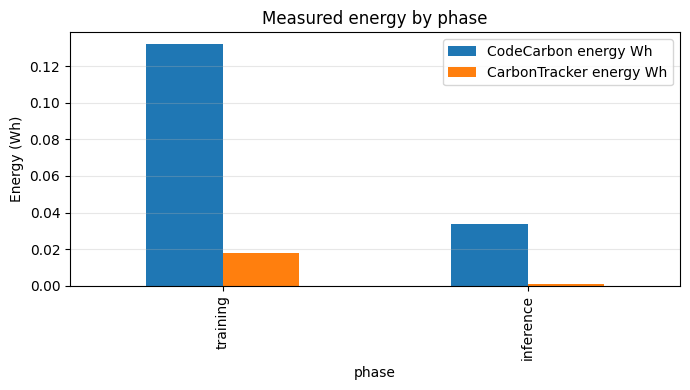

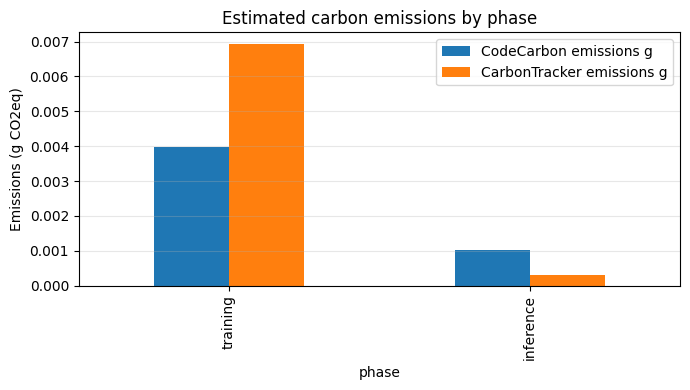

In [53]:
import matplotlib.pyplot as plt

plot_df = pd.DataFrame([
    {
        "phase": "training",
        "CodeCarbon energy Wh": training_carbon.get("cc_energy_kwh", np.nan) * 1000,
        "CodeCarbon emissions g": training_carbon.get("cc_emissions_g", np.nan),
        "CarbonTracker energy Wh": training_carbon.get("ct_energy_kwh", np.nan) * 1000,
        "CarbonTracker emissions g": training_carbon.get("ct_emissions_g", np.nan),
        "duration_s": training_carbon.get("duration_s", np.nan),
    },
    {
        "phase": "inference",
        "CodeCarbon energy Wh": inference_carbon.get("cc_energy_kwh", np.nan) * 1000,
        "CodeCarbon emissions g": inference_carbon.get("cc_emissions_g", np.nan),
        "CarbonTracker energy Wh": inference_carbon.get("ct_energy_kwh", np.nan) * 1000,
        "CarbonTracker emissions g": inference_carbon.get("ct_emissions_g", np.nan),
        "duration_s": inference_carbon.get("duration_s", np.nan),
    },
])

display(plot_df)

ax = plot_df.set_index("phase")[["CodeCarbon energy Wh", "CarbonTracker energy Wh"]].plot(kind="bar", figsize=(7, 4))
ax.set_ylabel("Energy (Wh)")
ax.set_title("Measured energy by phase")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(WORK_DIR / "patchtst_har_energy_by_phase.png", bbox_inches="tight")
plt.show()

ax = plot_df.set_index("phase")[["CodeCarbon emissions g", "CarbonTracker emissions g"]].plot(kind="bar", figsize=(7, 4))
ax.set_ylabel("Emissions (g CO2eq)")
ax.set_title("Estimated carbon emissions by phase")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(WORK_DIR / "patchtst_har_emissions_by_phase.png", bbox_inches="tight")
plt.show()

In [54]:
# Per-sample inference reporting based on the tracked inference phase.
# This replaces the old cell that referenced undefined variables such as carbon_path and total_eval_time_s.

n_samples = len(test_ds)

tracked_inference_summary = pd.DataFrame([{
    "dataset": "UCI-HAR test set",
    "model": "PatchTSTHARSeq2Seq",
    "n_samples": n_samples,
    "batch_size": BATCH_SIZE,
    "device": str(device),
    "total_inference_time_s": inference_carbon.get("duration_s", np.nan),
    "avg_inference_time_per_sample_s": inference_carbon.get("duration_s", np.nan) / max(n_samples, 1),
    "codecarbon_total_energy_wh": inference_carbon.get("cc_energy_wh", np.nan),
    "codecarbon_emissions_gCO2eq": inference_carbon.get("cc_emissions_g", np.nan),
    "carbontracker_total_energy_wh": inference_carbon.get("ct_energy_wh", np.nan),
    "carbontracker_emissions_gCO2eq": inference_carbon.get("ct_emissions_g", np.nan),
}])

display(tracked_inference_summary.T)

tracked_inference_summary.to_csv(WORK_DIR / "patchtst_har_inference_per_sample_summary.csv", index=False)
print("Saved:", WORK_DIR / "patchtst_har_inference_per_sample_summary.csv")

,0
dataset,UCI-HAR test set
model,PatchTSTHARSeq2Seq
n_samples,9
batch_size,4
device,cuda
total_inference_time_s,2.304708
avg_inference_time_per_sample_s,0.256079
codecarbon_total_energy_wh,0.033745
codecarbon_emissions_gCO2eq,0.001015
carbontracker_total_energy_wh,0.000789


Saved: /kaggle/working/patchtst_har_inference_per_sample_summary.csv


In [55]:
INFERENCE_REPEATS = 100

model.eval()
n_test_samples = len(test_ds)
total_inferences = INFERENCE_REPEATS * n_test_samples

with torch.no_grad():
    for _ in range(INFERENCE_REPEATS):
        for x, y, y_edge, mask in test_dl:
            x = x.to(device)
            _ = model(x)

In [57]:
import time
import numpy as np
import pandas as pd
from codecarbon import EmissionsTracker

# ============================================================
# Measure repeated inference: total + per-sample
# ============================================================

INFERENCE_REPEATS = 100
n_test_samples = len(test_ds)
total_inferences = INFERENCE_REPEATS * n_test_samples

model.eval()

# Optional warm-up: not tracked
with torch.no_grad():
    for x, y, y_edge, mask in test_dl:
        x = x.to(device)
        _ = model(x)
        break

if torch.cuda.is_available():
    torch.cuda.synchronize()

tracker = EmissionsTracker(
    project_name="patchtst_har_inference",
    output_dir=str(WORK_DIR),
    output_file="patchtst_har_inference_emissions.csv",
    log_level="error",
)

tracker.start()
start_time = time.time()

with torch.no_grad():
    for _ in range(INFERENCE_REPEATS):
        for x, y, y_edge, mask in test_dl:
            x = x.to(device)
            _ = model(x)

if torch.cuda.is_available():
    torch.cuda.synchronize()

duration_s = time.time() - start_time
emissions_kg = tracker.stop()

# Read CodeCarbon CSV for energy
cc_path = WORK_DIR / "patchtst_har_inference_emissions.csv"
cc_df = pd.read_csv(cc_path)
last_row = cc_df.iloc[-1]

energy_kwh = last_row.get("energy_consumed", np.nan)
energy_wh = energy_kwh * 1000 if pd.notna(energy_kwh) else np.nan
emissions_g = emissions_kg * 1000 if emissions_kg is not None else np.nan

summary = pd.DataFrame([{
    "dataset": "UCI-HAR test set",
    "model": "PatchTSTHARSeq2Seq",
    "n_test_samples": n_test_samples,
    "inference_repeats": INFERENCE_REPEATS,
    "total_inferences": total_inferences,
    "batch_size": BATCH_SIZE,
    "device": str(device),

    "total_inference_time_s": duration_s,
    "latency_s_per_sample": duration_s / total_inferences,

    "codecarbon_total_energy_wh": energy_wh,
    "codecarbon_energy_wh_per_sample": energy_wh / total_inferences,

    "codecarbon_total_emissions_gCO2eq": emissions_g,
    "codecarbon_emissions_gCO2eq_per_sample": emissions_g / total_inferences,
}])

display(summary.T)

summary.to_csv(
    WORK_DIR / "patchtst_har_repeated_inference_per_sample_summary.csv",
    index=False
)

print("Saved:", WORK_DIR / "patchtst_har_repeated_inference_per_sample_summary.csv")

,0
dataset,UCI-HAR test set
model,PatchTSTHARSeq2Seq
n_test_samples,9
inference_repeats,100
total_inferences,900
batch_size,4
device,cuda
total_inference_time_s,2.415778
latency_s_per_sample,0.002684
codecarbon_total_energy_wh,0.078269


Saved: /kaggle/working/patchtst_har_repeated_inference_per_sample_summary.csv
